# IT326 – Phase 2: Data Summarization and Preprocessing


# **Q1** **Data** **Analaysis**

# **1-** **Statistic** **summery**





In [57]:
import pandas as pd

df = pd.read_csv("Raw_dataset.csv")

print(df.info())


numeric_columns = df.select_dtypes(include='number').columns

summary = pd.DataFrame({
    'Count': df[numeric_columns].count(),
    'Mean': df[numeric_columns].mean(),
    'Std': df[numeric_columns].std(),
    'Min': df[numeric_columns].min(),
    '25%': df[numeric_columns].quantile(0.25),
    '50%': df[numeric_columns].median(),
    '75%': df[numeric_columns].quantile(0.75),
    'Max': df[numeric_columns].max()
})

summary



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 10 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Temperature                    5000 non-null   float64
 1   Humidity                       5000 non-null   float64
 2   PM2.5                          5000 non-null   float64
 3   PM10                           5000 non-null   float64
 4   NO2                            5000 non-null   float64
 5   SO2                            5000 non-null   float64
 6   CO                             5000 non-null   float64
 7   Proximity_to_Industrial_Areas  5000 non-null   float64
 8   Population_Density             5000 non-null   int64  
 9   Air Quality                    5000 non-null   object 
dtypes: float64(8), int64(1), object(1)
memory usage: 390.8+ KB
None


,Count,Mean,Std,Min,25%,50%,75%,Max
Temperature,5000,30.029020,6.720661,13.40,25.10,29.00,34.000,58.60
Humidity,5000,70.056120,15.863577,36.00,58.30,69.80,80.300,128.10
PM2.5,5000,20.142140,24.554546,0.00,4.60,12.00,26.100,295.00
PM10,5000,30.218360,27.349199,-0.20,12.30,21.70,38.100,315.80
NO2,5000,26.412100,8.895356,7.40,20.10,25.30,31.900,64.90
SO2,5000,10.014820,6.750303,-6.20,5.10,8.00,13.725,44.90
CO,5000,1.500354,0.546027,0.65,1.03,1.41,1.840,3.72
Proximity_to_Industrial_Areas,5000,8.425400,3.610944,2.50,5.40,7.90,11.100,25.80
Population_Density,5000,497.423800,152.754084,188.00,381.00,494.00,600.000,957.00


From our statistical summary, the mean temperature is 30.03, while the median is 29.00. For PM2.5, the mean is 20.14 and the median is 12.00, showing a difference between the average and middle values. The PM2.5 values range from 0.00 to 295.00, while Q1 is 4.60 and Q3 is 26.10. For Population Density, the mean is 497.42, the median is 494.00, and the values range from 188.00 to 957.00. These results help us understand the central tendency, spread, and variation of our numerical attributes.

# 2. Missing Values Analysis


Missing Values:
Temperature                      0
Humidity                         0
PM2.5                            0
PM10                             0
NO2                              0
SO2                              0
CO                               0
Proximity_to_Industrial_Areas    0
Population_Density               0
Air Quality                      0
dtype: int64


Text(0, 0.5, 'Number of Missing Values')

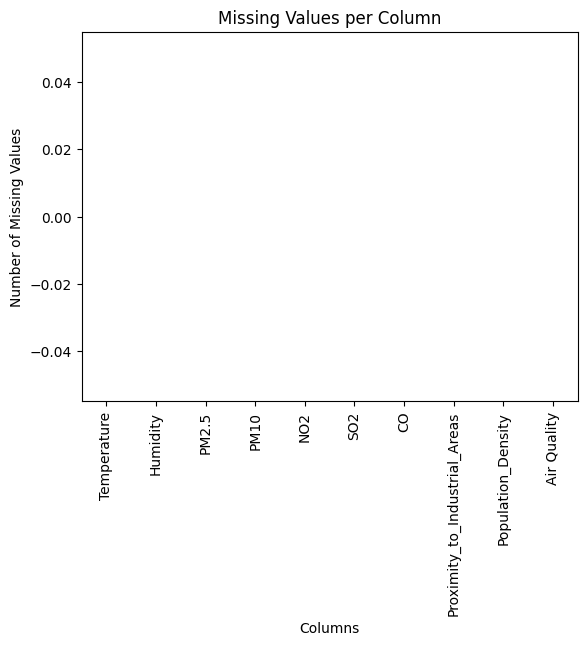

In [58]:
import pandas as pd

df = pd.read_csv("Raw_dataset.csv")

df.head()

import matplotlib.pyplot as plt
missing = df.isnull().sum()
print("\nMissing Values:")
print(missing)

plt.figure()
missing.plot(kind='bar')
plt.title("Missing Values per Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")

All attributes have zero missing values, indicating that the dataset is complete with respect to missing data. Therefore, no missing value treatment was needed

# 3. Bar Plot

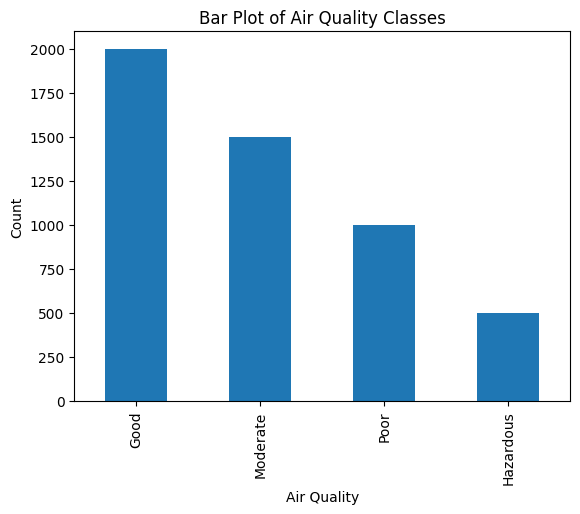

In [61]:
df['Air Quality'].value_counts().plot(kind='bar')
plt.xlabel('Air Quality')
plt.ylabel('Count')
plt.title('Bar Plot of Air Quality Classes')
plt.show()

The bar plot shows the distribution of the Air Quality classes. The Good class has the highest number of instances, followed by Moderate, Poor, and Hazardous. This indicates that the class distribution is not equal, and some classes contain more instances than others.

# 4. Histogram

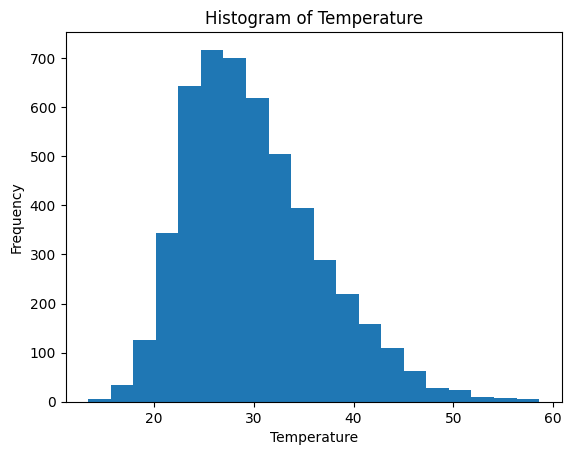

In [62]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("Raw_dataset.csv")
plt.hist(df['Temperature'], bins=20)
plt.xlabel('Temperature')
plt.ylabel('Frequency')
plt.title('Histogram of Temperature')
plt.show()

The histogram shows the distribution of Temperature values in the dataset. Most temperature values are concentrated approximately between 25 and 35, while fewer values appear at the higher temperatures. The distribution is slightly right-skewed, which indicates that some higher temperature values are less frequent.

# 5. Box plot



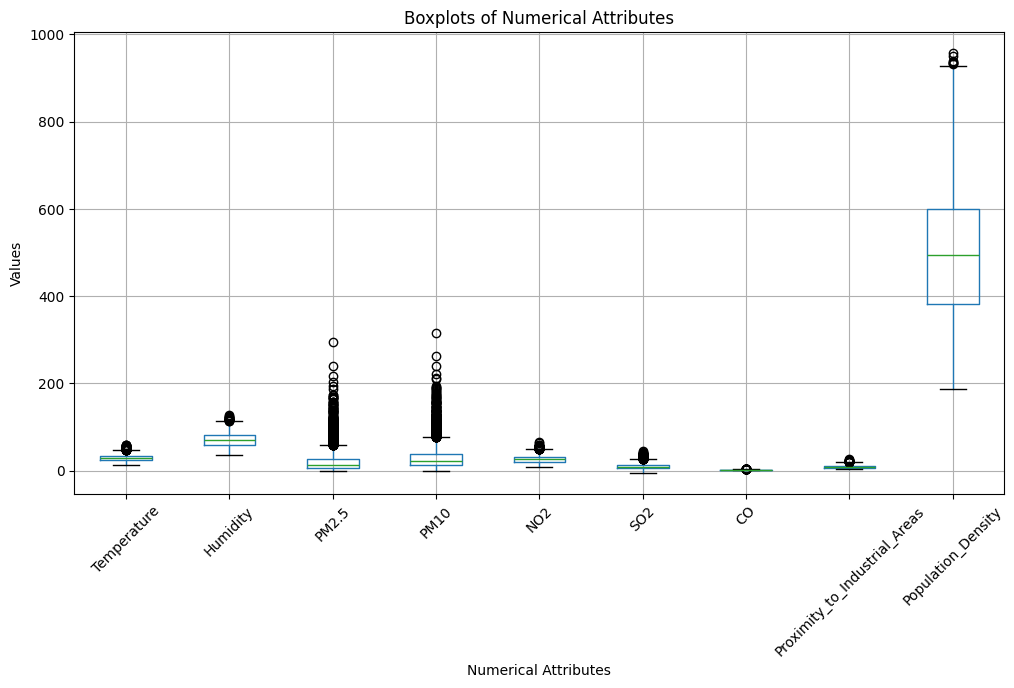

In [63]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("Raw_dataset.csv")

numeric_columns = df.select_dtypes(include=['int64', 'float64']).columns

plt.figure(figsize=(12, 6))
df[numeric_columns].boxplot()
plt.title('Boxplots of Numerical Attributes')
plt.xlabel('Numerical Attributes')
plt.ylabel('Values')
plt.xticks(rotation=45)
plt.show()



# Outlier

The boxplot shows the distribution of numeric features and highlights outliers. Outliers are values far from most data points and may need preprocessing such as removal or scaling. It also helps us see the spread and skewness of each feature.

# 6. Scatter plot

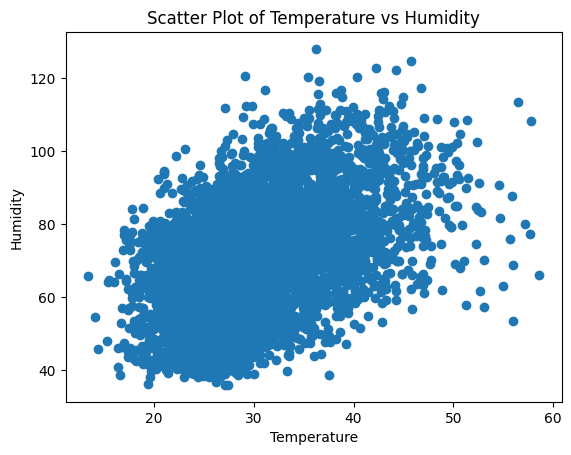

In [64]:
plt.scatter(df['Temperature'], df['Humidity'])
plt.xlabel('Temperature')
plt.ylabel('Humidity')
plt.title('Scatter Plot of Temperature vs Humidity')
plt.show()

The scatter plot shows the relationship between Temperature and Humidity. The points show a general positive relationship, where humidity tends to increase as temperature increases. However, the points are widely scattered, so the relationship is not very strong.

# 7. Class label distribution

In [66]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('Raw_dataset.csv')


Class Label Distribution:
Air Quality
Good         2000
Moderate     1500
Poor         1000
Hazardous     500
Name: count, dtype: int64


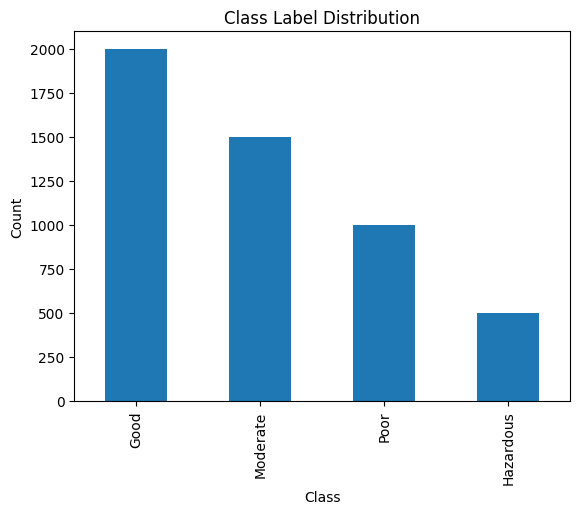

In [67]:
import pandas as pd

print("Class Label Distribution:")
print(df['Air Quality'].value_counts())
plt.figure()
df['Air Quality'].value_counts().plot(kind='bar')
plt.title("Class Label Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

The class label distribution shows the number of instances in each air quality class: Good, Moderate, Poor, and Hazardous. The distribution helps us understand how the data is distributed among the different classes and whether there is any class imbalance.

Based on the exploratory data analysis, the dataset contains no missing values. However, some numerical attributes may contain outliers, and the class distribution should be considered during preprocessing. Therefore, appropriate preprocessing techniques such as outlier handling and feature scaling can be applied to improve the quality of the dataset and prepare it for the data mining tasks.

# Q2 Data Preprocessing



#1. Variable Transformation

In [68]:
numeric_cols = df.select_dtypes(include='number').columns

skewness = df[numeric_cols].skew().sort_values(ascending=False)

print("Skewness of numerical attributes:")
print(skewness)

Skewness of numerical attributes:
PM2.5                            2.890910
PM10                             2.534815
SO2                              1.166772
CO                               0.879068
Temperature                      0.752187
NO2                              0.638783
Proximity_to_Industrial_Areas    0.469752
Humidity                         0.280528
Population_Density               0.204231
dtype: float64


The skewness of the numerical attributes was examined. PM2.5, PM10, and SO2 showed relatively high positive skewness. Therefore, Log Transformation using log1p(x) was applied to these attributes to reduce skewness and improve the distribution of the data.

# 2. Log Transformation

In [69]:
import numpy as np

transformed_df = df.copy()

for col in ['PM2.5', 'PM10', 'SO2']:
    min_value = transformed_df[col].min()

    if min_value < 0:
        transformed_df[col] = transformed_df[col] - min_value

    transformed_df[col] = np.log1p(transformed_df[col])

print("Log transformation applied to: PM2.5, PM10, SO2")

print("\nSkewness after transformation:")
print(transformed_df[['PM2.5', 'PM10', 'SO2']].skew())

Log transformation applied to: PM2.5, PM10, SO2

Skewness after transformation:
PM2.5   -0.111306
PM10     0.099418
SO2      0.204137
dtype: float64


After transformation, the skewness values decreased substantially:

PM2.5: 2.8909 → -0.1113

PM10: 2.5348 → 0.0994

SO2: 1.1668 → 0.2041

# 3. Normalization

In [70]:
from sklearn.preprocessing import MinMaxScaler

numeric_cols = transformed_df.select_dtypes(include='number').columns


normalized_df = transformed_df.copy()

scaler = MinMaxScaler()

normalized_df[numeric_cols] = scaler.fit_transform(
    transformed_df[numeric_cols]
)

print("Min-Max Normalization applied successfully.")

print("\nMinimum values after normalization:")
print(normalized_df[numeric_cols].min())

print("\nMaximum values after normalization:")
print(normalized_df[numeric_cols].max())

Min-Max Normalization applied successfully.

Minimum values after normalization:
Temperature                      0.0
Humidity                         0.0
PM2.5                            0.0
PM10                             0.0
NO2                              0.0
SO2                              0.0
CO                               0.0
Proximity_to_Industrial_Areas    0.0
Population_Density               0.0
dtype: float64

Maximum values after normalization:
Temperature                      1.0
Humidity                         1.0
PM2.5                            1.0
PM10                             1.0
NO2                              1.0
SO2                              1.0
CO                               1.0
Proximity_to_Industrial_Areas    1.0
Population_Density               1.0
dtype: float64


Min-Max Normalization was applied to all numerical attributes. This transformation scales the numerical values to a common range between 0 and 1 while preserving their relative relationships.

The minimum value of each numerical attribute became 0 and the maximum value became 1.

# 4.Discretization

Note: discretization was applied in a separate DataFrame (`discretized_df`) to evaluate its effect. The final dataset is built from the normalized (continuous) data, so the discretized Temperature is not kept in `Preprocessed_dataset.csv`. The preprocessing steps retained in the final dataset are log transformation, Min-Max normalization, and feature selection.

In [72]:
from sklearn.preprocessing import KBinsDiscretizer

discretized_df = normalized_df.copy()

# Discretize Temperature into 3 equal-width bins
discretizer = KBinsDiscretizer(
    n_bins=3,
    encode='ordinal',
    strategy='uniform'
)

discretized_df['Temperature'] = discretizer.fit_transform(
    normalized_df[['Temperature']]
)

print("Discretization applied successfully.")
print("\nTemperature values after discretization:")
print(discretized_df['Temperature'].value_counts().sort_index())

Discretization applied successfully.

Temperature values after discretization:
Temperature
0.0    2337
1.0    2456
2.0     207
Name: count, dtype: int64


# 5. Feature Selection

In [73]:
import pandas as pd

target_mapping = {
    'Good': 0,
    'Moderate': 1,
    'Poor': 2,
    'Hazardous': 3
}

feature_selection_df = discretized_df.copy()

feature_selection_df['Air_Quality_numeric'] = (
    feature_selection_df['Air Quality'].map(target_mapping)
)

correlations = feature_selection_df.corr(numeric_only=True)['Air_Quality_numeric'] \
    .drop('Air_Quality_numeric') \
    .abs() \
    .sort_values(ascending=False)

print("Correlation of features with Air Quality:")
print(correlations)

Correlation of features with Air Quality:
CO                               0.912534
NO2                              0.785030
Proximity_to_Industrial_Areas    0.773637
SO2                              0.723187
Temperature                      0.670836
Population_Density               0.645546
Humidity                         0.625546
PM10                             0.613076
PM2.5                            0.402963
Name: Air_Quality_numeric, dtype: float64


Feature Selection was applied to reduce the number of attributes while keeping the features that have a meaningful relationship with the target variable, Air Quality.

The absolute correlation between each numerical feature and Air Quality was calculated. A threshold of 0.5 was used for feature selection. Features with an absolute correlation of 0.5 or higher were retained.

In [74]:
selected_features = correlations[correlations >= 0.5].index.tolist()

print("Selected features:")
print(selected_features)

print("\nRemoved feature:")
print([col for col in correlations.index if col not in selected_features])

final_df = normalized_df[selected_features + ['Air Quality']].copy()

print("\nFinal dataset shape:")
print(final_df.shape)
print("\nFinal dataset:")
print(final_df.head())

Selected features:
['CO', 'NO2', 'Proximity_to_Industrial_Areas', 'SO2', 'Temperature', 'Population_Density', 'Humidity', 'PM10']

Removed feature:
['PM2.5']

Final dataset shape:
(5000, 9)

Final dataset:
         CO       NO2  Proximity_to_Industrial_Areas       SO2  Temperature  \
0  0.348534  0.200000                       0.163090  0.707606     0.362832   
1  0.322476  0.406957                       0.150215  0.715203     0.329646   
2  0.319218  0.295652                       0.115880  0.755264     0.214602   
3  0.162866  0.106087                       0.369099  0.638913     0.303097   
4  0.117264  0.252174                       0.437768  0.644912     0.289823   

   Population_Density  Humidity      PM10 Air Quality  
0            0.170351  0.250814  0.512196    Moderate  
1            0.550065  0.429967  0.450651    Moderate  
2            0.560468  0.420195  0.617366    Moderate  
3            0.472042  0.033659  0.349876        Good  
4            0.149545  0.376764  0.4940

The selected features were:

CO — 0.9125

NO2 — 0.7850

Proximity to Industrial Areas — 0.7736

SO2 — 0.7232

Temperature — 0.6708 (computed after discretization; 0.7536 before it)

Population Density — 0.6455

Humidity — 0.6255

PM10 — 0.6131


The feature PM2.5, with a correlation of 0.4030, was removed because its absolute correlation was below the selected threshold.

# 5. Raw vs Preprocessed Dataset

In [75]:
print("RAW DATASET")
print("Shape:", df.shape)
print("Columns:", list(df.columns))
print("\n Row Dataset Snapshot:")
display(df.head())

print("\nFINAL PREPROCESSED DATASET")
print("Shape:", final_df.shape)
print("Columns:", list(final_df.columns))
print("\nPreprocesses Dataset Snapshot")
display(final_df.head())

print("\nNumber of columns removed:")
print(df.shape[1] - final_df.shape[1])

print("\nRemoved columns:")
print([col for col in df.columns if col not in final_df.columns])

RAW DATASET
Shape: (5000, 10)
Columns: ['Temperature', 'Humidity', 'PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'Proximity_to_Industrial_Areas', 'Population_Density', 'Air Quality']

 Row Dataset Snapshot:


,Temperature,Humidity,PM2.5,PM10,NO2,SO2,CO,Proximity_to_Industrial_Areas,Population_Density,Air Quality
0,29.8,59.1,5.2,17.9,18.9,9.2,1.72,6.3,319,Moderate
1,28.3,75.6,2.3,12.2,30.8,9.7,1.64,6.0,611,Moderate
2,23.1,74.7,26.7,33.8,24.4,12.6,1.63,5.2,619,Moderate
3,27.1,39.1,6.1,6.3,13.5,5.3,1.15,11.1,551,Good
4,26.5,70.7,6.9,16.0,21.9,5.6,1.01,12.7,303,Good



FINAL PREPROCESSED DATASET
Shape: (5000, 9)
Columns: ['CO', 'NO2', 'Proximity_to_Industrial_Areas', 'SO2', 'Temperature', 'Population_Density', 'Humidity', 'PM10', 'Air Quality']

Preprocesses Dataset Snapshot


,CO,NO2,Proximity_to_Industrial_Areas,SO2,Temperature,Population_Density,Humidity,PM10,Air Quality
0,0.348534,0.200000,0.163090,0.707606,0.362832,0.170351,0.250814,0.512196,Moderate
1,0.322476,0.406957,0.150215,0.715203,0.329646,0.550065,0.429967,0.450651,Moderate
2,0.319218,0.295652,0.115880,0.755264,0.214602,0.560468,0.420195,0.617366,Moderate
3,0.162866,0.106087,0.369099,0.638913,0.303097,0.472042,0.033659,0.349876,Good
4,0.117264,0.252174,0.437768,0.644912,0.289823,0.149545,0.376764,0.494002,Good



Number of columns removed:
1

Removed columns:
['PM2.5']


The original dataset contained 5,000 rows and 10 columns.

After applying the preprocessing steps, including Variable Transformation, Min-Max Normalization, and Feature Selection, the final dataset contains 5,000 rows and 9 columns.

Therefore, one feature was removed:

PM2.5

The numerical features in the final dataset were normalized to a range between 0 and 1, while the Air Quality target variable was retained.

# 6. Final Dataset

In [76]:
final_df.to_csv("Preprocessed_dataset.csv", index=False)

print("Final preprocessed dataset saved successfully.")
print("File: Preprocessed_dataset.csv")

Final preprocessed dataset saved successfully.
File: Final_Preprocessed_Dataset.csv


The final preprocessed dataset was saved as:

Preprocessed_dataset.csv

This dataset is ready for the next stages of the project, such as classification and clustering.